<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A010_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Уразов Андрій  
**Група:** 3-10  
**Дата:** 10.11.26

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [3]:
import tensorflow as tf
import keras
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")
print(f"x_test shape:  {x_test.shape},  y_test shape:  {y_test.shape}")

x_train shape: (60000, 28, 28), y_train shape: (60000,)
x_test shape:  (10000, 28, 28),  y_test shape:  (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

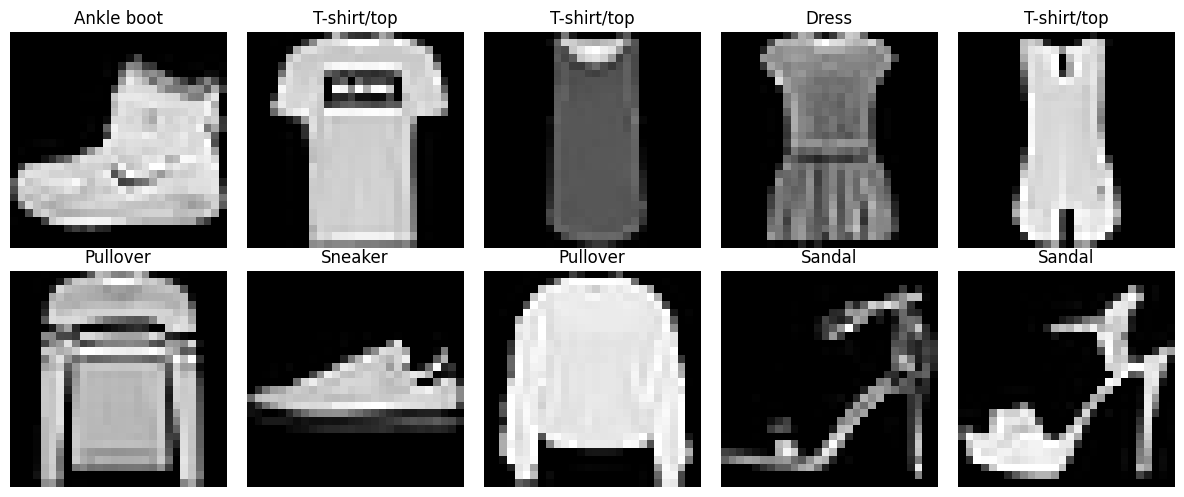

In [7]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [8]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
print(f"Train range: [{x_train.min():.1f}, {x_train.max():.1f}], dtype: {x_train.dtype}")
print(f"Test range:  [{x_test.min():.1f}, {x_test.max():.1f}], dtype: {x_test.dtype}")

Train range: [0.0, 1.0], dtype: float32
Test range:  [0.0, 1.0], dtype: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [9]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

**Пояснення вибору параметрів:**

Архітектура з двома прихованими повнозв'язними шарами (256 та 128 нейронів) з активацією ReLU забезпечує достатню ємність моделі для виділення нелінійних патернів зображень $28 \times 28$. Шари Dropout ($0.3$ та $0.2$) вимикають випадкову частку нейронів під час прямого проходу, що запобігає коадаптації ваг і перенавчанню. Оптимізатор Adam зі швидкістю навчання $\eta = 0.001$ є стандартним вибором, який забезпечує швидку адаптивну збіжність за рахунок обчислення моментів градієнтів.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [10]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]
history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7874 - loss: 0.5927 - val_accuracy: 0.8459 - val_loss: 0.4241 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8408 - loss: 0.4339 - val_accuracy: 0.8647 - val_loss: 0.3779 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8576 - loss: 0.3947 - val_accuracy: 0.8713 - val_loss: 0.3497 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8649 - loss: 0.3702 - val_accuracy: 0.8677 - val_loss: 0.3550 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8696 - loss: 0.3537 - val_accuracy: 0.8811 - val_loss: 0.3311 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8732 - loss: 0.3423 - val_accuracy: 0.8802 - val_loss: 0.3257 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8772 - loss: 0.3292 - 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [12]:
model.save('fashion_mnist_model.keras')
print("Модель успішно збережена у файлі fashion_mnist_model.keras")

Модель успішно збережена у файлі fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

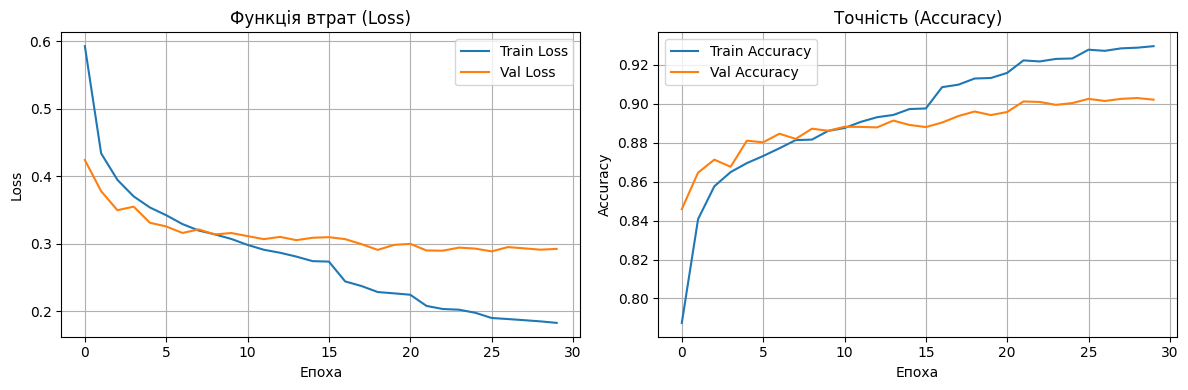

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Функція втрат (Loss)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точність (Accuracy)')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [14]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Тестовий loss: {test_loss:.4f}")
print(f"Тестова accuracy: {test_acc:.4f} (поріг >= 0.87: {'Виконано' if test_acc >= 0.87 else 'Не виконано'})")
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)
print("\nКласифікаційний звіт:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Тестовий loss: 0.3221
Тестова accuracy: 0.8944 (поріг >= 0.87: Виконано)
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8510    0.8450    0.8480      1000
     Trouser     0.9898    0.9710    0.9803      1000
    Pullover     0.7979    0.8170    0.8073      1000
       Dress     0.8873    0.9130    0.9000      1000
        Coat     0.8175    0.8240    0.8207      1000
      Sandal     0.9817    0.9680    0.9748      1000
       Shirt     0.7308    0.7030    0.7166      1000
     Sneaker     0.9478    0.9620    0.9548      1000
         Bag     0.9769    0.9740    0.9755      1000
  Ankle boot     0.9622    0.9670    0.9646      1000

    accuracy                         0.8944     10000
   macro avg     0.8943    0.8944    0.8943     10000
weighted avg     0.8943    0.8944    0.8943     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

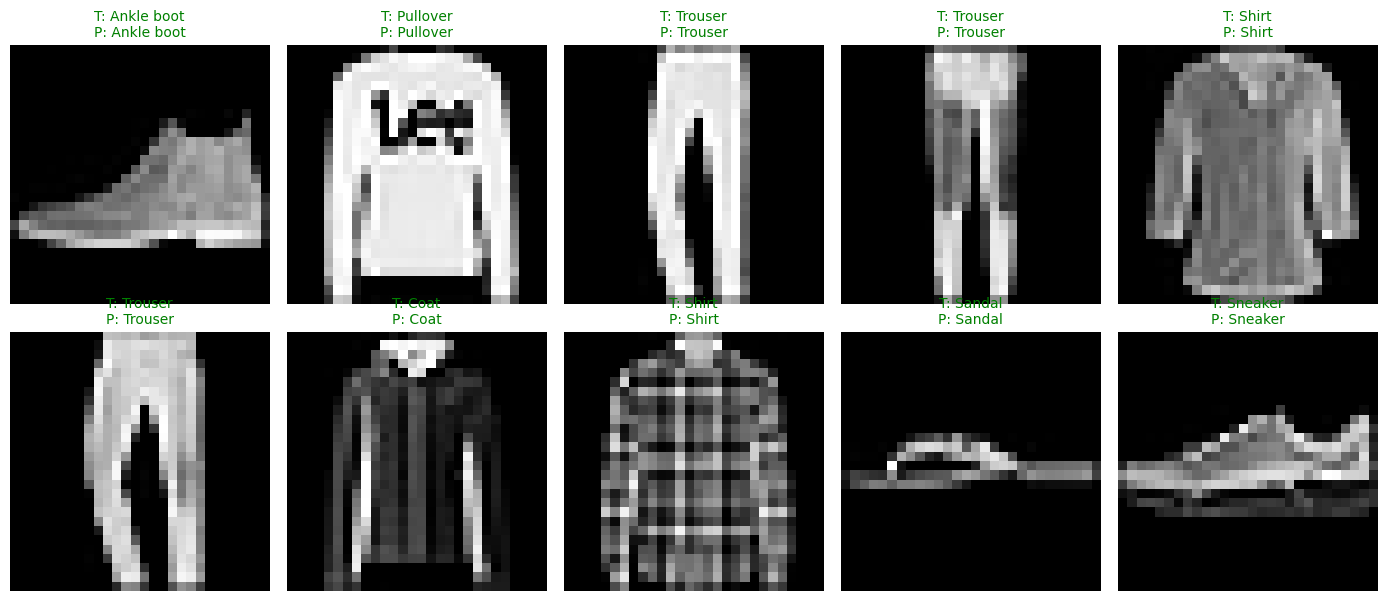

In [15]:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_cls = class_names[y_test[i]]
    pred_cls = class_names[y_pred[i]]
    is_correct = (y_test[i] == y_pred[i])
    color = 'green' if is_correct else 'red'
    plt.title(f"T: {true_cls}\nP: {pred_cls}", color=color, fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
_Отримана точність на тестовій вибірці становить 0.8944 (89.44%) при значенні втрат 0.3221, що успішно виконує вимогу лабораторної роботи (поріг $\ge 0.87$)._

_Найбільшу кількість помилок модель допускає на класі Shirt (найнижчі показники: precision 0.7308, recall 0.7030, F1-score 0.7166), а також на суміжних категоріях верхнього одягу Pullover (F1-score 0.8073) та Coat (F1-score 0.8207) через високу візуальну схожість текстур, контурів і крою на низькороздільних зображеннях $28 \times 28$. Натомість такі класи, як Trouser (F1-score 0.9803), Bag (0.9755) та взуття (Sandal, Sneaker, Ankle boot з F1-score > 0.95), розпізнаються найбільш впевнено та стабільно._

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [16]:
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [17]:
from sklearn.model_selection import train_test_split
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
print(f"Train subset: {x_tr.shape}, Val subset: {x_val.shape}")

Train subset: (48000, 28, 28), Val subset: (12000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [18]:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(28, 28)))
    model.add(Flatten())
    num_layers = hp.Int('num_layers', min_value=1, max_value=3)
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        model.add(Dense(units=units, activation='relu', kernel_regularizer=l2(l2_reg)))
        model.add(Dropout(rate=dropout_rate))
    model.add(Dense(10, activation='softmax'))
    lr = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [19]:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='kt_fashion_mnist',
    project_name='tuning_run',
    overwrite=True
)
tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
l2_reg (Float)
{'default': 1e-05, 'conditions': [], 'min_value': 1e-05, 'max_value': 0.01, 'step': None, 'sampling': 'log'}
dropout_rate (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [20]:
callbacks_tuner = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)
]
tuner.search(
    x_tr, y_tr,
    epochs=15,
    validation_data=(x_val, y_val),
    callbacks=callbacks_tuner,
    batch_size=64
)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for param, val in best_hps.values.items():
    print(f" - {param}: {val}")
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()
history_best = best_model.fit(
    x_tr, y_tr,
    epochs=20,
    validation_data=(x_val, y_val),
    callbacks=callbacks_tuner,
    batch_size=64
)

Trial 3 Complete [00h 00m 43s]
val_accuracy: 0.8337500095367432

Best val_accuracy So Far: 0.8918333053588867
Total elapsed time: 00h 02m 27s
Найкращі гіперпараметри:
 - num_layers: 3
 - l2_reg: 2.196813908337335e-05
 - dropout_rate: 0.2
 - units_0: 160
 - learning_rate: 0.001
 - units_1: 32
 - units_2: 32


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 160)            │       125,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,138 (516.16 KB)

 Trainable params: 132,138 (516.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7010 - loss: 0.8264 - val_accuracy: 0.8378 - val_loss: 0.4711 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8145 - loss: 0.5434 - val_accuracy: 0.8518 - val_loss: 0.4154 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8342 - loss: 0.4863 - val_accuracy: 0.8569 - val_loss: 0.4015 - learning_rate: 0.0010
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8497 - loss: 0.4498 - val_accuracy: 0.8741 - val_loss: 0.3671 - learning_rate: 0.0010
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8543 - loss: 0.4308 - val_accuracy: 0.8733 - val_loss: 0.3652 - learning_rate: 0.0010
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8589 - loss: 0.4207 - val_accuracy: 0.8777 - val_loss: 0.3536 - learning_rate: 0.0010
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8633 - loss: 0.4028 - 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test Loss (Tuned): 0.3568
Test Accuracy (Tuned): 0.8860


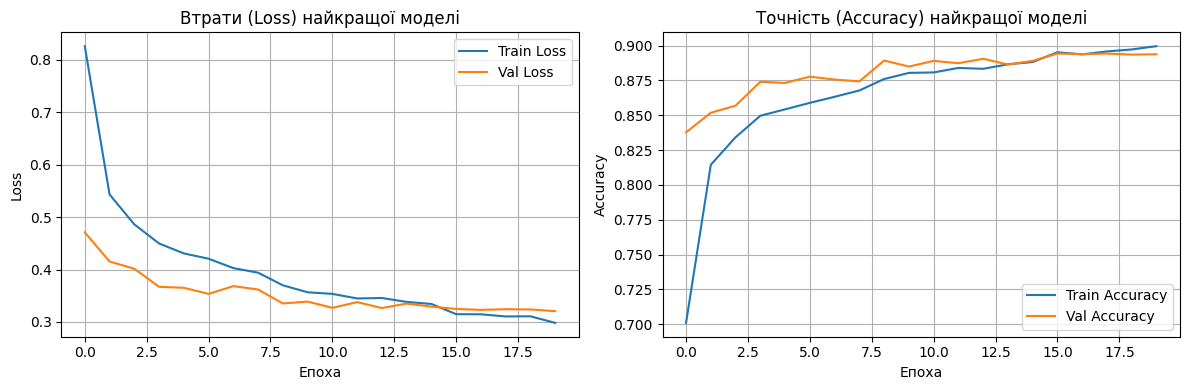

In [21]:
test_loss_tuned, test_acc_tuned = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss (Tuned): {test_loss_tuned:.4f}")
print(f"Test Accuracy (Tuned): {test_acc_tuned:.4f}")
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_best.history['loss'], label='Train Loss')
plt.plot(history_best.history['val_loss'], label='Val Loss')
plt.title('Втрати (Loss) найкращої моделі')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history_best.history['accuracy'], label='Train Accuracy')
plt.plot(history_best.history['val_accuracy'], label='Val Accuracy')
plt.title('Точність (Accuracy) найкращої моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей


| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 3 |
| Кількість нейронів | 256, 128 | 160, 32, 32 |
| Швидкість навчання | 0.001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8944 | 0.8860 |
| Втрати на тестовій вибірці (loss) | 0.3221 | 0.3568 |
| Кількість епох навчання | 15 (рання зупинка) | 20 |


**Власні висновки:**  
1. Чи досягнуто точності **не нижче 0,87** у завданні 1?

_Вимогу щодо мінімальної точності повністю виконано — тестова accuracy склала 0.8944 (89.44%) при порозі не нижче 0.87._

2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?

_Тюнінг гіперпараметрів дав тестову точність 0.8860 (88.60%), що також перевищує базовий поріг 0.87, проте виявилося дещо нижчим за базову модель із завдання 1 (0.8944). При цьому Keras Tuner підібрав значно компактнішу архітектуру: 132 тис. параметрів проти понад 230 тис. у базовій версії, забезпечивши порівнянну якість при помітно меншій обчислювальній складності._

3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?

_Найкращою конфігурацією став 3-шаровий перцептрон (160, 32 та 32 нейрони) зі швидкістю навчання $\eta = 0.001$, Dropout $0.2$ та коефіцієнтом L2-регуляризації $\approx 2.2 \times 10^{-5}$. Результати між запусками можуть різнитися через обмежену кількість ітерацій (max_trials = 3), стохастичну випадкову вибірку комбінацій параметрів у RandomSearch, випадкову ініціалізацію ваг шарів та розбиття підвибірок на батчі під час оптимізації Adam._

4. Які класи Fashion MNIST класифікувати найскладніше?

_Найважче класифікувати візуально схожі категорії одягу зі спільними елементами крою: Shirt (F1-score 0.7166), Pullover (F1-score 0.8073) та Coat (F1-score 0.8207). Зображення розміром $28 \times 28$ пікселів у відтінках сірого втрачають текстурні деталі (комірці, ґудзики), через що повнозв'язна нейромережа часто плутає ці три класи між собою._